Day 7 — H₂ Hartree–Fock and Potential Energy Curve

1. Scientific Goal

We used H₂ as a simple molecular system to connect quantum chemistry calculations with the concepts learned in Days 1–6.

Main workflow:

H₂ geometry → molecular Hamiltonian → RHF/SCF → HF energy → bond stretching → Potential Energy Curve → electronic correlation

---

2. Molecular Model

System:

- Molecule: H₂
- Electrons: 2
- Charge: 0
- Spin: 0
- Basis: STO-3G
- Geometry: two H atoms separated along the z-axis

For the main calculation:

R = 1.4 Bohr

Important: PySCF coordinates must have an explicit unit. We used:

unit="Bohr"

---

3. Born–Oppenheimer Hamiltonian

The full molecular Hamiltonian is:

H = Tₑ + Tₙ + Vₑₙ + Vₑₑ + Vₙₙ

Under the Born–Oppenheimer approximation, the nuclei are fixed:

Hₑ = Tₑ + Vₑₙ + Vₑₑ

where:

- Tₑ = electron kinetic energy
- Vₑₙ = electron–nuclear attraction
- Vₑₑ = electron–electron repulsion
- Vₙₙ = nuclear–nuclear repulsion

For fixed geometry, Vₙₙ is added to the total molecular energy.

---

4. RHF / SCF

Hartree–Fock approximates the many-electron wavefunction using a Slater determinant:

|Ψ⟩ ≈ |Φ_HF⟩

RHF is appropriate for the H₂ ground state because the two electrons are paired with opposite spins.

The SCF procedure iteratively updates the orbitals until the energy is converged:

initial orbitals → Fock operator → new orbitals → repeat → convergence

For H₂ at R = 1.4 Bohr:

E_RHF = −1.1167143251 Eh

This is the RHF total molecular energy for the chosen geometry, basis set, and Hamiltonian approximation.

It is not the exact ground-state energy because Hartree–Fock does not fully describe electron correlation.

---

5. Bond Stretching

We calculated RHF energies at several H–H distances:

R (Bohr)| E_RHF (Eh)
0.7| −0.83713030
1.0| −1.06599946
1.4| −1.11671433
1.8| −1.07898221
2.2| −1.01648572

The energy decreases, reaches a minimum in the sampled region, and then increases again.

Therefore:

E = E(R)

The Potential Energy Curve describes how the molecular energy changes as the H–H bond length changes.

---

6. Bond Stretching and Correlation

Near equilibrium, a single Hartree–Fock determinant can describe a large part of the H₂ ground state.

As the bond is stretched, different electronic configurations become increasingly important.

Near dissociation, static correlation becomes important and a single RHF determinant becomes insufficient.

Conceptually:

bond stretching
→ stronger static correlation
→ multiple important configurations
→ richer many-body wavefunction

---

7. Connection to Entanglement and MPS

The many-body wavefunction can be represented as a coefficient tensor:

|Ψ⟩ = Σ Cₙ₁ₙ₂...ₙₙ |n₁n₂...nₙ⟩

A bipartition followed by SVD gives the Schmidt decomposition:

|Ψ⟩ = Σ λᵢ |uᵢ⟩ₐ |vᵢ⟩ᵦ

where λᵢ are the Schmidt coefficients.

These coefficients determine entanglement measures such as:

S = −Σ λᵢ² log₂(λᵢ²)

Sequential SVD converts the many-body coefficient tensor into an MPS:

A[1] — A[2] — ... — A[N]

with:

D ≥ χ

where:

- D = MPS bond dimension
- χ = Schmidt rank

Thus, the quantum-chemistry calculation provides the molecular wavefunction, while tensor-network methods provide a way to analyze and represent its many-body structure.

---

8. Mental Map

H₂ geometry
→ Hamiltonian
→ RHF/SCF
→ wavefunction + energy
→ stretch bond
→ E(R)
→ electronic correlation
→ Schmidt decomposition
→ entanglement
→ MPS / tensor-network representation

---

9. Scientific Result

The H₂ calculation demonstrates that molecular energy is geometry-dependent and that bond stretching changes the electronic structure.

The important next step is to move beyond RHF and obtain a correlated many-body wavefunction. This will allow orbital partitions, reduced density matrices, Schmidt coefficients, and entanglement measures to be studied as functions of molecular bond length.

One-sentence conclusion:

H₂ bond stretching provides a simple route from molecular electronic structure and Hartree–Fock calculations to the study of electronic correlation, entanglement, and tensor-network representations.

In [ ]:
!pip install pyscf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 17.6 MB/s eta 0:00:00


In [ ]:
from pyscf import gto

mol = gto.M(
atom='''
H  0  0  0
H  0  0  1.4
''',
basis='sto-3g',
charge=0,
spin=0
)

In [ ]:
print(mol)

In [ ]:
print("Number of atoms:", mol.natm)
print("Number of electrons:", mol.nelectron)
print("Number of basis functions:", mol.nao_nr())

Number of atoms: 2
Number of electrons: 2
Number of basis functions: 2


In [ ]:
from pyscf import scf

mf = scf.RHF(mol)
energy_hf = mf.kernel()

print("HF energy:", energy_hf)

converged SCF energy = -0.941480654707798
HF energy: -0.9414806547077981


In [ ]:
import pyscf

print("PySCF version:", pyscf.__version__)

PySCF version: 2.14.0


In [ ]:
import sys

!{sys.executable} -m pip install pyscf

In [ ]:
import pyscf

print("PySCF version:", pyscf.__version__)

PySCF version: 2.14.0


In [ ]:
from pyscf import gto

mol = gto.M(
atom='''
H  0  0  0
H  0  0  1.4
''',
basis='sto-3g',
charge=0,
spin=0
)

print("Number of atoms:", mol.natm)
print("Number of electrons:", mol.nelectron)
print("Number of basis functions:", mol.nao_nr())

Number of atoms: 2
Number of electrons: 2
Number of basis functions: 2


In [ ]:
from pyscf import scf

mf = scf.RHF(mol)

energy_hf = mf.kernel()

print("HF energy:", energy_hf)

converged SCF energy = -0.941480654707798
HF energy: -0.9414806547077981


In [ ]:
print("Geometry:")
print(mol.atom_coords())

print("Basis:", mol.basis)
print("Charge:", mol.charge)
print("Spin:", mol.spin)
print("Electrons:", mol.nelectron)
print("HF energy:", energy_hf)

Geometry:
[[0.         0.         0.        ]
 [0.         0.         2.64561657]]
Basis: sto-3g
Charge: 0
Spin: 0
Electrons: 2
HF energy: -0.9414806547077981


In [ ]:
from pyscf import gto

mol_bohr = gto.M(
atom='''
H  0  0  0
H  0  0  1.4
''',
basis='sto-3g',
charge=0,
spin=0,
unit='Bohr'
)

from pyscf import scf

mf_bohr = scf.RHF(mol_bohr)
energy_hf_bohr = mf_bohr.kernel()

print("HF energy:", energy_hf_bohr)

converged SCF energy = -1.11671432506255
HF energy: -1.116714325062551


In [ ]:
from pyscf import gto, scf

bond_lengths = [0.7, 1.0, 1.4, 1.8, 2.2]

energies = []

for R in bond_lengths:
    mol = gto.M(
    atom=f'''
    H  0  0  0
    H  0  0  {R}
    ''',
    basis='sto-3g',
    charge=0,
    spin=0,
    unit='Bohr'
 )
mf = scf.RHF(mol)
E = mf.kernel()
energies.append(E)
print(f"R = {R:.1f} Bohr, E = {E:.8f} Eh")

converged SCF energy = -1.01648572151702
R = 2.2 Bohr, E = -1.01648572 Eh


In [ ]:
from pyscf import gto, scf

bond_lengths = [0.7, 1.0, 1.4, 1.8, 2.2]

for R in bond_lengths:
    mol = gto.M(
        atom=f"H 0 0 0; H 0 0 {R}",
        basis="sto-3g",
        charge=0,
        spin=0,
        unit="Bohr",
        verbose=0
    )

    mf = scf.RHF(mol)
    E = mf.kernel()

    print("R =", R, "Bohr   E =", E, "Eh")

R = 0.7 Bohr   E = -0.8371302982208928 Eh
R = 1.0 Bohr   E = -1.0659994621433109 Eh
R = 1.4 Bohr   E = -1.116714325062551 Eh
R = 1.8 Bohr   E = -1.078982211916911 Eh
R = 2.2 Bohr   E = -1.0164857215170233 Eh


ValueError: x and y must have same first dimension, but have shapes (5,) and (1,)

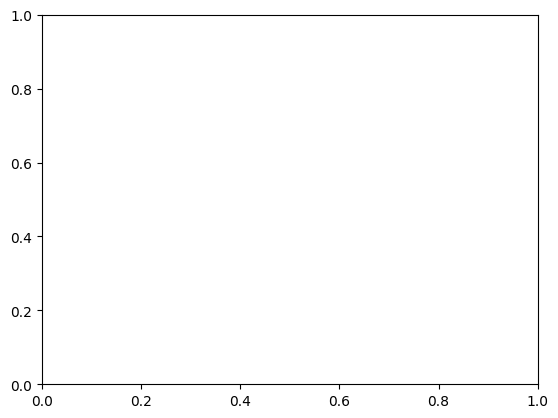

In [ ]:
import matplotlib.pyplot as plt

plt.plot(bond_lengths, energies, marker="o")

plt.xlabel("H-H bond length (Bohr)")
plt.ylabel("RHF energy (Hartree)")
plt.title("H₂ Potential Energy Curve")

plt.show()

In [ ]:
import matplotlib.pyplot as plt

bond_lengths = [0.7, 1.0, 1.4, 1.8, 2.2]

energies = [
    -0.8371302982208928,
    -1.0659994621433109,
    -1.116714325062551,
    -1.078982211916911,
    -1.0164857215170233
]

plt.plot(bond_lengths, energies, marker="o")

plt.xlabel("H-H bond length (Bohr)")
plt.ylabel("RHF energy (Hartree)")
plt.title("H₂ Potential Energy Curve")

plt.show()